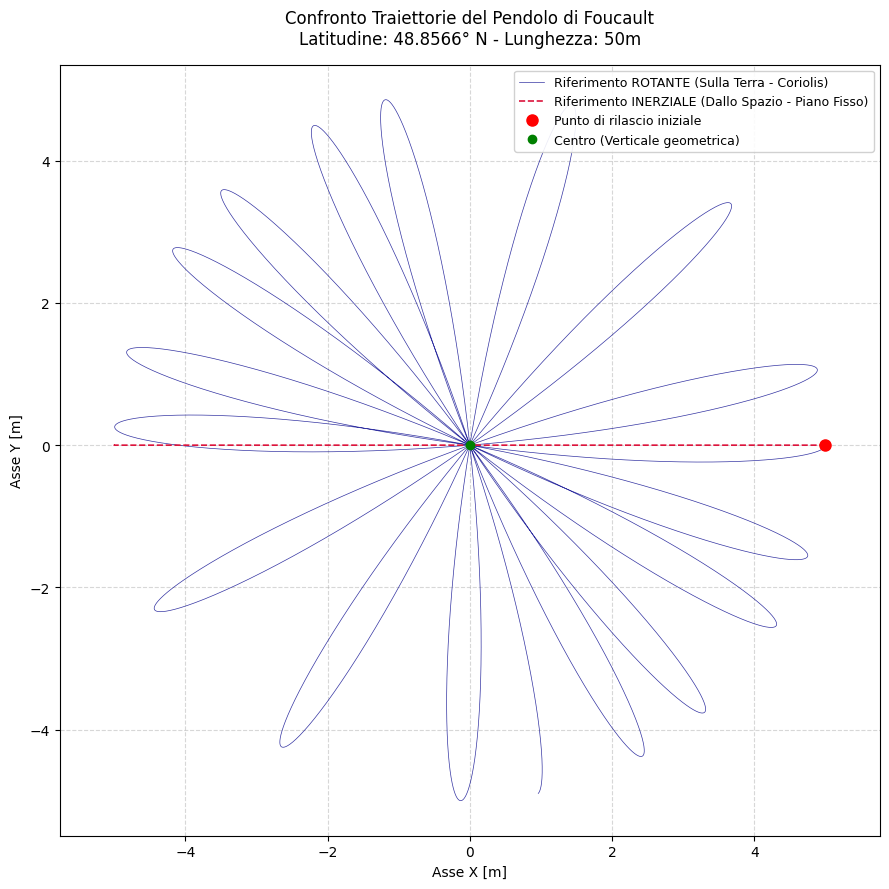

In [115]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# =============================================================================
# 1. PARAMETRI DEL SISTEMA (dal tuo notebook)
# =============================================================================
g = 9.81              # Accelerazione di gravità [m/s^2]
L = 50                # Lunghezza del pendolo [m]
omega_terra = 0.05     # Velocità angolare della Terra "accelerata" [rad/s]
latitudine = 48.8566  # Latitudine (Parigi)

# Conversione e pulsazione
lam = np.radians(latitudine)
omega_0 = np.sqrt(g / L)

# Velocità di precessione (componente z)
omega_z = omega_terra * np.sin(lam)

# =============================================================================
# 2. EQUAZIONI DIFFERENZIALI (SISTEMA ROTANTE)
# =============================================================================
def foucault_equations(t, state):
    x, dxdt, y, dydt = state
    d2xdt2 = - (omega_0**2) * x + 2 * omega_z * dydt
    d2ydt2 = - (omega_0**2) * y - 2 * omega_z * dxdt
    return [dxdt, d2xdt2, dydt, d2ydt2]

# =============================================================================
# 3. CONDIZIONI INIZIALI (VELOCITÀ INERZIALE NULLA)
# =============================================================================
x0 = 5.0  # Spostamento iniziale lungo X
y0 = 0.0  # Spostamento iniziale lungo Y

# Per fare in modo che la velocità INERZIALE iniziale sia zero, dobbiamo
# sottrarre la velocità di trascinamento rotatoria nel sistema rotante:
# v_rot = v_inerziale - (omega x r) -> se v_inerziale = 0 -> v_rot = -omega x r
# Sapendo che ruota attorno all'asse Z con velocità omega_z:
# dxdt0 = omega_z * y0
# dydt0 = -omega_z * x0
dxdt0 = omega_z * y0
dydt0 = -omega_z * x0

stato_iniziale = [x0, dxdt0, y0, dydt0]

t_span = (0, 120) #
t_eval = np.linspace(t_span[0], t_span[1], 100000) #

# Risoluzione numerica nel sistema rotante
soluzione = solve_ivp(foucault_equations, t_span, stato_iniziale, t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)

t = soluzione.t
x_rot = soluzione.y[0]
y_rot = soluzione.y[2]

# =============================================================================
# 4. TRASFORMAZIONE NEL SISTEMA INERZIALE
# =============================================================================
# Applichiamo la matrice di rotazione inversa del tempo per vedere il moto dalle stelle fisse
x_inerziale = x_rot * np.cos(omega_z * t) - y_rot * np.sin(omega_z * t)
y_inerziale = x_rot * np.sin(omega_z * t) + y_rot * np.cos(omega_z * t)

# =============================================================================
# 5. GRAFICO UNICO COMPARATIVO
# =============================================================================
plt.figure(figsize=(9, 9))

# Traiettoria nel sistema Rotante (Terrestre) - Effetto Margherita
plt.plot(x_rot, y_rot, color='darkblue', linewidth=0.5, alpha=0.8, 
         label='Riferimento ROTANTE (Sulla Terra - Coriolis)')

# Traiettoria nel sistema Inerziale (Spazio) - Retta Perfetta
plt.plot(x_inerziale, y_inerziale, color='crimson', linewidth=1.2, linestyle='--', 
         label='Riferimento INERZIALE (Dallo Spazio - Piano Fisso)')

# Punti notevoli (Rilascio e Centro)
plt.plot(x0, y0, 'ro', markersize=8, label='Punto di rilascio iniziale')
plt.plot(0, 0, 'go', markersize=6, label='Centro (Verticale geometrica)')

# Configurazione grafica e labels
plt.title("Confronto Traiettorie del Pendolo di Foucault\n"
          f"Latitudine: {latitudine}° N - Lunghezza: {L}m", fontsize=12, pad=15)
plt.xlabel("Asse X [m]", fontsize=10)
plt.ylabel("Asse Y [m]", fontsize=10)

plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.legend(loc='upper right', fontsize=9, framealpha=0.9)

# Salvataggio e visualizzazione
plt.tight_layout()
plt.savefig("../Appunti/img/pendoloDiFoucault.png", dpi=300)
plt.show()